In [71]:
import json
import re
import numpy as np
import os
import sys
from collections import defaultdict
from sklearn.cluster import AgglomerativeClustering
from sentence_transformers import SentenceTransformer
from sentence_transformers.models import StaticEmbedding
from postprocessing import postprocessing
import math

In [2]:
DISTANCE_THRESHOLD = 0.12

In [3]:
def load_json(path):
    if not os.path.exists(path):
        print(f"Lỗi: Không tìm thấy file tại {path}")
        return {}
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)
    

def save_json(data, file_path):
    with open(file_path, 'w', encoding='utf-8') as file:
        json.dump(data, file, ensure_ascii=False, indent=4)
        
        
def extract_references(long_answer):
    if not long_answer:
        return []
    return re.findall(r"\[([^\]]+)\]", long_answer)

def cluster_cohesion(embeddings):
    if len(embeddings) <= 1:
        return 0
    centroid = embeddings.mean(axis=0)
    dists = np.linalg.norm(embeddings - centroid, axis=1)
    return dists.mean()

import json
import numpy as np

def save_embedding_cache(cache, file_path):
    # Chuyển đổi tất cả ndarray sang list để JSON có thể serialize được
    cache_to_save = {k: v.tolist() if isinstance(v, np.ndarray) else v 
                     for k, v in cache.items()}
    
    with open(file_path, 'w', encoding='utf-8') as f:
        json.dump(cache_to_save, f, ensure_ascii=False, indent=4)

# Khi load lại, bạn cũng cần convert ngược từ list sang numpy array
def load_embedding_cache(file_path):
    try:
        with open(file_path, 'r', encoding='utf-8') as f:
            cached_data = json.load(f)
        return {k: np.array(v) for k, v in cached_data.items()}
    except FileNotFoundError:
        return {}

In [72]:
def collect_candidates(cluster_file, mapping_data):
    raw_data = load_json(cluster_file)
    processed_data = {}

    for qidx, clusters in raw_data.items():
        cand_list = []
        for cid, cluster in clusters.items():
            if "llm" not in cluster:
                continue

            ans = cluster["llm"].get("short_answer", "").strip().lower()
            long_answer = cluster["llm"].get("long_answer", "")
            context = cluster.get("context", "").lower()
            
            if not ans or ans == "insufficient information":
                continue

            if ans in mapping_data:
                norm_ans = mapping_data[ans]
            else:
                norm_ans = postprocessing(ans)
                norm_ans = mapping_data.get(norm_ans, norm_ans)
            
            norm_ans= postprocessing(ans)
            
            raw_sources = extract_references(long_answer)
            sources = list(set(raw_sources))
            has_wiki = any("WIKI" in s for s in sources)
            has_gg = any("GG" in s for s in sources)

            cand_list.append({
                "text": norm_ans,
                "long_answer": long_answer,
                "context": context,
                "sources": sources,
                "has_wiki": has_wiki,
                "has_gg": has_gg
            })
        
        # không phân cụm
        # processed_data[qidx] = cand_list if len(cand_list) >= 2 else None
       
        processed_data[qidx] = cand_list if len(cand_list) >= 1 else None
        
    return processed_data

#  Công thức 6: Gini / Concentration Adjusted
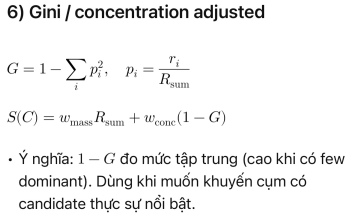

In [5]:
# import math
# import os
# import json

# # =========================
# # CONFIG GINI / CONCENTRATION ADJUSTED (Công thức 6)
# # =========================
# W_MASS = 0.5          # Trọng số cho tổng khối lượng bằng chứng (R_sum)
# W_CONC = 0.5        # Trọng số cho mức độ tập trung (1 - G)
# MIN_SCORE_THRESHOLD = 2.0

# def calculate_gini_adjusted_score(individual_ref_counts):
#     """
#     Tính toán điểm dựa trên công thức 6: Gini / Concentration Adjusted
#     S(C) = w_mass * R_sum + w_conc * (1 - G)
#     """
#     if not individual_ref_counts or sum(individual_ref_counts) == 0:
#         return 0.0

#     # 1. Tính R_sum (Tổng số refer trong cụm)
#     r_sum = sum(individual_ref_counts)
    
#     # 2. Tính p_i và chỉ số tập trung (1 - G)
#     # (1 - G) = sum( (r_i / r_sum)^2 )
#     concentration = sum([(ri / r_sum)**2 for ri in individual_ref_counts])
    
#     # 3. Tính điểm S(C) refs theo công thức 6
#     s_c_refs = (W_MASS * r_sum) + (W_CONC * concentration)
   
    
#     return s_c_refs

# def cluster_and_evaluate(processed_data, model, dict_golden):
#     fused_results = {}
#     list_id_miss = set()
#     cache_miss = {}

#     for qidx, cand_list in processed_data.items():
#         if cand_list is None:
#             fused_results[qidx] = {"abstain": True}
#             list_id_miss.add(qidx)
#             # Lưu cache miss cho trường hợp không có candidate
#             cache_miss[qidx] = {
#                 "reason": "no_candidate",
#                 "golden": dict_golden.get(qidx, {}).get("True", []),
#                 "num_clusters": 0,
#                 "clusters": [],
#                 "candidates": None
#             }
#             continue
        
#         texts = [c["text"] for c in cand_list]
#         embeddings = model.encode(texts)
#         raw_clusters = []

#         if len(cand_list) >= 2:        
#             from sklearn.cluster import AgglomerativeClustering
#             labels = AgglomerativeClustering(
#                 n_clusters=None,
#                 distance_threshold=0.12, # Giả định threshold cố định
#                 metric="cosine", linkage="average"
#             ).fit(embeddings).labels_

#             for lbl in set(labels):
#                 indices = [i for i, l in enumerate(labels) if l == lbl]
                
#                 # Danh sách số refer (ri) của từng candidate trong cụm
#                 individual_ref_counts = [len(cand_list[i]["sources"]) for i in indices]

#                 nc = len(indices)
#                 # Tính điểm theo công thức Gini Adjusted mới
#                 c_score = calculate_gini_adjusted_score(individual_ref_counts)
                
#                 raw_clusters.append({
#                     "indices": indices,
#                     "evidence_count": nc,
#                     "cluster_score": c_score,
#                     "unique_source": sum(individual_ref_counts)
#                 })

#         # 2. CHỌN CLUSTER TỐT NHẤT DỰA TRÊN SCORE TỔNG HỢP
#         best_cluster_info = None
#         if raw_clusters:
#             candidate_best = max(raw_clusters, key=lambda x: x["cluster_score"])
#             if candidate_best["cluster_score"] >= MIN_SCORE_THRESHOLD:
#                 best_cluster_info = candidate_best

#         # 3. XỬ LÝ KẾT QUẢ & CHỌN FINAL ANSWER
#         if best_cluster_info is None:
#             fused_results[qidx] = {"abstain": True}
#             list_id_miss.add(qidx)
#             # Lưu cache miss chi tiết để debug
#             cache_miss[qidx] = {
#                 "reason": "no_cluster_selected",
#                 "golden": dict_golden.get(qidx, {}).get("True", []),
#                 "num_clusters": len(raw_clusters),
#                 "clusters": raw_clusters,
#                 "candidates": cand_list
#             }
#             continue
        
#         chosen_indices = best_cluster_info["indices"]
#         # Chọn candidate có nhiều refer nhất (R_max) trong cụm tốt nhất
#         best_idx = max(chosen_indices, key=lambda idx: len(cand_list[idx]["sources"]))

#         fused_results[qidx] = {
#             "final_answer": cand_list[best_idx]["text"],
#             "context": cand_list[best_idx]["context"],
#             "abstain": False,
#             "debug_score": round(best_cluster_info["cluster_score"], 4)
#         }

#     # Lưu log các câu không chọn được kết quả (tùy chọn)
#     os.makedirs(r'src\cluster\cache\select_final_ans', exist_ok=True)
#     file_miss = fr'src\cluster\cache\select_final_ans\{len(list_id_miss)}q_khong_lay.json'
#     with open(file_miss, 'w', encoding='utf-8') as f:
#         json.dump(cache_miss, f, ensure_ascii=False, indent=4)

#     return fused_results, list(list_id_miss)

# CÔNG THỨC 2

In [68]:
import math
import numpy as np
from sklearn.cluster import AgglomerativeClustering

# Công thức 2b
MIN_SCORE_THRESHOLD = 3

def log_plus(x):
    return math.log(1 + x)

def calculate_new_score(individual_ref_counts, nc):
    max_ri = max(individual_ref_counts) if individual_ref_counts else 0
    term_max = log_plus(max_ri)
    term_sum_all = sum(log_plus(ri) for ri in individual_ref_counts)
    term_nc = log_plus(nc)
    return term_max + term_sum_all + term_nc

def cluster_and_evaluate(processed_data, model, golden_dict, embedding_cache=None):
    """
    embedding_cache: dict truyền từ ngoài vào để lưu trữ/tái sử dụng embeddings.
                     Nếu là None, hàm sẽ tự khởi tạo cache tạm thời.
    """
    if embedding_cache is None:
        embedding_cache = {}
        
    fused_results = {}
    list_id_miss = set()
    
    for qidx, cand_list in processed_data.items():
        if not cand_list:
            fused_results[qidx] = {"abstain": True}
            list_id_miss.add(qidx)
            continue
        
        # --- QUẢN LÝ CACHE THEO QIDX ---
        if qidx in embedding_cache:
            embeddings = embedding_cache[qidx]
        else:
            texts = [c["text"] for c in cand_list]
            embeddings = model.encode(texts)
            embedding_cache[qidx] = embeddings
        
        # 1. PHÂN CỤM
        raw_clusters = []
        if len(cand_list) >= 2:         
            # Đảm bảo DISTANCE_THRESHOLD đã được định nghĩa trong phạm vi sử dụng
            labels = AgglomerativeClustering(
                n_clusters=None,
                distance_threshold=DISTANCE_THRESHOLD,
                metric="cosine", linkage="average"
            ).fit(embeddings).labels_

            for lbl in set(labels):
                indices = [i for i, l in enumerate(labels) if l == lbl]
                individual_ref_counts = [len(cand_list[i]["sources"]) for i in indices]
                nc = len(indices)
                c_score = calculate_new_score(individual_ref_counts, nc)
                
                raw_clusters.append({
                    "indices": indices,
                    "cluster_score": c_score
                })
        else:
            # 1 candidate vẫn tính điểm bình thường
            ref_counts = [len(cand_list[0]["sources"])]
            raw_clusters.append({
                "indices": [0],
                "cluster_score": calculate_new_score(ref_counts, 1)
            })

        # 2. CHỌN CLUSTER TỐT NHẤT
        best_cluster_info = None
        if raw_clusters:
            candidate_best = max(raw_clusters, key=lambda x: x["cluster_score"])
            if candidate_best["cluster_score"] >= MIN_SCORE_THRESHOLD:
                best_cluster_info = candidate_best

        if best_cluster_info is None:
            fused_results[qidx] = {"abstain": True}
            list_id_miss.add(qidx)
            continue
        
        # 3. GỘP CANDIDATE CÙNG TEXT TRONG CỤM (UPDATE SOURCE)
        chosen_indices = best_cluster_info["indices"]
        merged_in_cluster = {}

        for idx in chosen_indices:
            cand = cand_list[idx]
            norm_text = cand["text"]
            
            if norm_text not in merged_in_cluster:
                merged_in_cluster[norm_text] = {
                    "text": cand["text"],
                    "sources": set(cand.get("sources", [])),
                    "context": cand.get("context", "")
                }
            else:
                merged_in_cluster[norm_text]["sources"].update(cand.get("sources", []))

        # 4. CHỌN KẾT QUẢ CUỐI CÙNG (Max source count sau merge)
        final_candidate = max(merged_in_cluster.values(), key=lambda x: len(x["sources"]))

        fused_results[qidx] = {
            "final_answer": final_candidate["text"],
            "context": final_candidate["context"],
            "sources": list(final_candidate["sources"]),
            "abstain": False,
            "debug_score": round(best_cluster_info["cluster_score"], 4)
        }

    return fused_results, list(list_id_miss), embedding_cache

# CÔNG THỨC  6

In [73]:
import math
import os
import json
from sklearn.cluster import AgglomerativeClustering

# =========================
# CONFIG GINI / CONCENTRATION ADJUSTED (Công thức 66)
# =========================
W_MASS = 0.7          # Trọng số cho tổng khối lượng bằng chứng (R_sum)
W_CONC = 0.3          # Trọng số cho mức độ tập trung (1 - G)
MIN_SCORE_THRESHOLD = 2.0
DISTANCE_THRESHOLD = 0.12

def calculate_gini_adjusted_score(individual_ref_counts):
    """
    Tính toán điểm dựa trên công thức 6: Gini / Concentration Adjusted
    S(C) = w_mass * R_sum + w_conc * (1 - G)
    """
    if not individual_ref_counts or sum(individual_ref_counts) == 0:
        return 0.0

    # 1. Tính R_sum (Tổng số refer trong cụm)
    r_sum = sum(individual_ref_counts)
    
    # 2. Tính p_i và chỉ số tập trung (1 - G)
    # (1 - G) = sum( (r_i / r_sum)^2 )
    concentration = sum([(ri / r_sum)**2 for ri in individual_ref_counts])
    
    # 3. Tính điểm S(C) theo công thức 6
    s_c_refs = (W_MASS * r_sum) + (W_CONC * concentration)
    
    return s_c_refs

def cluster_and_evaluate(processed_data, model, dict_golden, embedding_cache=None):
    if embedding_cache is None:
        embedding_cache = {}

    fused_results = {}
    list_id_miss = set()
    cache_miss = {}
    
    cnt = 0
    cnt_true = 0
    for qidx, cand_list in processed_data.items():
        if not cand_list:
            fused_results[qidx] = {"abstain": True}
            list_id_miss.add(qidx)
            cache_miss[qidx] = {
                "reason": "no_candidate",
                "golden": dict_golden.get(qidx, {}).get("True", []),
                "num_clusters": 0,
                "clusters": [],
                "candidates": None
            }
            continue
        
        # --- BƯỚC CACHE EMBEDDING ---
        if qidx in embedding_cache:
            embeddings = embedding_cache[qidx]
        else:
            texts = [c["text"] for c in cand_list]
            embeddings = model.encode(texts)
            embedding_cache[qidx] = embeddings
            
        raw_clusters = []

        # 1. PHÂN CỤM (Xử lý cả 1 candidate và n candidates)
        if len(cand_list) >= 2:         
            labels = AgglomerativeClustering(
                n_clusters=None,
                distance_threshold=DISTANCE_THRESHOLD,
                metric="cosine", linkage="average"
            ).fit(embeddings).labels_

            for lbl in set(labels):
                indices = [i for i, l in enumerate(labels) if l == lbl]
                individual_ref_counts = [len(cand_list[i]["sources"]) for i in indices]
                
                c_score = calculate_gini_adjusted_score(individual_ref_counts)
                
                raw_clusters.append({
                    "indices": indices,
                    "evidence_count": len(indices),
                    "cluster_score": c_score,
                    "unique_source": sum(individual_ref_counts)
                })
        else:
            # Trường hợp 1 candidate: 1 cluster bình thường
            ref_counts = [len(cand_list[0]["sources"])]
            raw_clusters.append({
                "indices": [0],
                "evidence_count": 1,
                "cluster_score": calculate_gini_adjusted_score(ref_counts),
                "unique_source": ref_counts[0]
            })
            cnt += 1
            if cand_list[0]['text'] in dict_golden[qidx]['True']:
                cnt_true += 1

        # 2. CHỌN CLUSTER TỐT NHẤT
        best_cluster_info = None
        if raw_clusters:
            candidate_best = max(raw_clusters, key=lambda x: x["cluster_score"])
            if candidate_best["cluster_score"] >= MIN_SCORE_THRESHOLD:
                best_cluster_info = candidate_best

        if best_cluster_info is None:
            fused_results[qidx] = {"abstain": True}
            list_id_miss.add(qidx)
            cache_miss[qidx] = {
                "reason": "no_cluster_selected",
                "golden": dict_golden.get(qidx, {}).get("True", []),
                "num_clusters": len(raw_clusters),
                "clusters": raw_clusters,
                "candidates": cand_list
            }
            continue
        
        # 3. MERGE CANDIDATES GIỐNG NHAU TRONG CLUSTER ĐÃ CHỌN
        chosen_indices = best_cluster_info["indices"]
        merged_in_cluster = {}

        for idx in chosen_indices:
            cand = cand_list[idx]
            norm_text = cand["text"].strip()
            
            if norm_text not in merged_in_cluster:
                merged_in_cluster[norm_text] = {
                    "text": cand["text"],
                    "sources": set(cand.get("sources", [])),
                    "context": cand.get("context", "")
                }
            else:
                merged_in_cluster[norm_text]["sources"].update(cand.get("sources", []))

        # 4. CHỌN FINAL ANSWER (Candidate có sources cao nhất sau merge)
        final_candidate = max(merged_in_cluster.values(), key=lambda x: len(x["sources"]))

        fused_results[qidx] = {
            "final_answer": final_candidate["text"],
            "context": final_candidate["context"],
            "sources": list(final_candidate["sources"]),
            "abstain": False,
            "debug_score": round(best_cluster_info["cluster_score"], 4)
        }

    # Lưu log miss (Giữ nguyên logic của bạn)
    os.makedirs(r'src\cluster\cache\select_final_ans', exist_ok=True)
    file_miss = fr'{len(list_id_miss)}q_khong_lay.json'
    with open(file_miss, 'w', encoding='utf-8') as f:
        json.dump(cache_miss, f, ensure_ascii=False, indent=4)

    # print(cnt_true, cnt, cnt_true/cnt)
    return fused_results, list(list_id_miss), embedding_cache

In [74]:
def compute_selected_summary(fused_results, dict_golden):
    total_with_evidence = len(fused_results)
    selected, correct_selected, total_wrong = 0, 0, 0
    wrong_has_golden_in_ctx, wrong_no_golden_in_ctx = 0, 0
    list_id_wrong = []

    for qidx, info in fused_results.items():
        if info.get("abstain", True):
            continue

        selected += 1
        pred = str(info.get("final_answer", "")).lower().strip()
        context = str(info.get("context", "")).lower()
        golden_list = [str(g).lower().strip() for g in dict_golden.get(qidx, {}).get("True", [])]

        if pred in golden_list:
            correct_selected += 1
        else:
            list_id_wrong.append(qidx)
            total_wrong += 1
            if any(g in context for g in golden_list):
                wrong_has_golden_in_ctx += 1
            else:
                wrong_no_golden_in_ctx += 1

    acc = correct_selected / selected if selected else 0.0
    coverage = selected / total_with_evidence if total_with_evidence else 0.0

    return {
        "total": total_with_evidence, "selected": selected, "correct": correct_selected,
        "acc": acc, "coverage": coverage, "wrong": total_wrong,
        "wrong_in_ctx": wrong_has_golden_in_ctx, "wrong_no_ctx": wrong_no_golden_in_ctx
    }, list_id_wrong

In [8]:
def load_pubmed_model():
    print("Loading embedding model (PubMedBERT)...")    
    return SentenceTransformer("pritamdeka/S-BioBert-snli-multinli-stsb",device="cpu")

In [75]:
BASE_FOLDER = "src/cluster/final"

# PATH_CLUSTER = fr"{BASE_FOLDER}/WH_answer_kmean_merge_google_wiki_7.json"
PATH_GOLDEN = "data/all_answer_golden_56_update.json"
PATH_MAPPING = 'data/mapping_answer_gol.json'

# PATH_CLUSTER = r"src\cluster\final\WH_answer_kmean_merge_google_wiki_7_new.json"
# PATH_CLUSTER = r"src\cluster\final\WH_answer_kmean_merge_google_wiki_7_old.json"

PATH_CLUSTER =r'src\cluster\final\WH_comeback_k_3.json' #double gg
PATH_CLUSTER_YN =r'src\cluster\final\YN_comeback_k_3.json' #double gg

# r'src\cluster\final\WH_answer_CT6_#5.json'
# PATH_CLUSTER =   r'src\cluster\final\WH_answer_kmean_merge_google_wiki_7_only_GG.json' #only gg
# PATH_CLUSTER =   r'src\cluster\final\YN_answer_kmean_merge_google_wiki_7_only_GG.json' #only gg

In [76]:
model = load_pubmed_model()
mapping_data = load_json(PATH_MAPPING)
dict_golden = load_json(PATH_GOLDEN)

Loading embedding model (PubMedBERT)...


In [77]:
print("Step 1: Collecting candidates...")
# processed_candidates_mapping = collect_candidates(PATH_CLUSTER, mapping_data)

Step 1: Collecting candidates...


In [78]:
processed_candidates_no_mapping = collect_candidates(PATH_CLUSTER, mapping_data)

In [79]:
processed_candidates_no_mapping_YN = collect_candidates(PATH_CLUSTER_YN, mapping_data)

In [80]:
#vtmthu MAPPING
results_WH, list_id_miss, embedding_cache_mapping = cluster_and_evaluate(processed_candidates_no_mapping, model, dict_golden, embedding_cache=embedding_cache_mapping)
print(f"Th={MIN_SCORE_THRESHOLD}, W_MASS={W_MASS}, W_CONC={W_CONC}")
print(len(list_id_miss))
# save_json(list_id_miss, f"list_id_miss_ct.json")
stats, list_id_wrong = compute_selected_summary(results, dict_golden)
print(f"Selected Answers   : {stats['selected']} (Coverage: {stats['coverage']*100:.2f}%)")
print(f"Correct Answers    : {stats['correct']} (Accuracy: {stats['acc']*100:.2f}%)")

Th=2.0, W_MASS=0.7, W_CONC=0.3
40
Selected Answers   : 140 (Coverage: 80.92%)
Correct Answers    : 116 (Accuracy: 82.86%)


In [81]:
results_YN, list_id_miss_2, embedding_cache_no_mapping = cluster_and_evaluate(processed_candidates_no_mapping_YN, model, dict_golden, embedding_cache=embedding_cache_no_mapping)
print(len(list_id_miss_2))
# save_json(list_id_miss_2, f"list_id_miss_ct.json")
stats, list_id_wrong = compute_selected_summary(results_YN, dict_golden)
print(f"Selected Answers   : {stats['selected']} (Coverage: {stats['coverage']*100:.2f}%)")
print(f"Correct Answers    : {stats['correct']} (Accuracy: {stats['acc']*100:.2f}%)")


15
Selected Answers   : 42 (Coverage: 73.68%)
Correct Answers    : 40 (Accuracy: 95.24%)


In [82]:
save_json(results_WH, 'WH_mapping.json')

In [ ]:
save_json(list_id_miss, f"list_id_miss_ct.json")

In [ ]:
save_json(list_id_miss_2, f"list_id_miss_ct.json")
print(len(list_id_miss_2))

40


In [ ]:
# save_json(tmp, "lis_id_miss_select_WH.json")

In [ ]:
# len(tmp)